<a href="https://colab.research.google.com/github/marthinaf03/ml-hotel-booking-cancellation/blob/main/hotel_booking_cancellation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Booking Cancellation Prediction

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Business Understanding

### 1.1 Problem definition

In the hotel industry, booking cancellations are a major source of lost revenue. A hotel room is a perishable product: if a room stays empty for one night, that revenue is lost forever and cannot be recovered later.

The impact of a cancellation depends on when it happens. If a guest cancels months in advance, the hotel still has time to sell the room again. If the cancellation arrives just a few days before the arrival, it is much harder to find a new guest, because most travellers book their stay well in advance.

The goal of this project is to predict whether a booking will be cancelled (`is_canceled`) using the information available at booking time, and to understand which types of bookings and customers are most at risk. The model is intended to support the hotel's revenue management and reservations team in two concrete actions:
- contacting high-risk guests before their arrival to confirm the booking;
- requiring a deposit for the bookings with the highest cancellation risk.

### 1.2 Cost of errors and choice of metrics

The model can make two types of errors:
- False negative: the model predicts that the guest will arrive, but the booking is cancelled. The hotel takes no action and the room may remain empty, causing lost revenue.
- False positive: the model predicts a cancellation, but the guest arrives. With the actions considered in this project (a reminder or a deposit request), the cost is small: an extra contact or a slightly stricter booking condition.

For this reason, false negatives are the most costly error, and Recall on the cancelled class is the main metric: we want to identify as many cancellations as possible. Since a model that flags every booking as "cancelled" would have perfect Recall but be useless, we also consider Precision, the F1-score (balance between Precision and Recall) and the PR-AUC, which is more informative than accuracy or ROC-AUC when the classes are imbalanced.

A more aggressive use of the model, such as overbooking, would make false positives much more expensive (a guest arriving without an available room). This scenario is not the main focus of the project, but it is discussed in the Deployment section.

## 2. Data Understanding

### 2.1 Data import


In [8]:
URL = "https://raw.githubusercontent.com/marthinaf03/ml-hotel-booking-cancellation/main/data/hotel_bookings.csv"
df = pd.read_csv(URL)
df.shape

(119390, 32)

### 2.2 Attribute description


In [9]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

**Observations**
- The dataset contains 119,390 bookings and 32 attributes; the target variable `is_canceled` is binary (0 = not cancelled, 1 = cancelled) and has no missing values.
- Missing values are present in four columns: `company`, `agent`, `country` and `children` (quantified below). The `NULL` strings in the original CSV are correctly read by pandas as missing values.
- `agent` and `company` are stored as numbers (`float64`), but they are **identifiers** of the travel agency and of the company that made the booking: they must be treated as categorical variables, not as numerical quantities.
- `children` is stored as `float64` only because of its missing values; it represents a count and will be converted to integer.
- Ten attributes are categorical (`object`): `hotel`, `arrival_date_month`, `meal`, `country`, `market_segment`, `distribution_channel`, `reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type`. They will need to be encoded before modeling.
- `reservation_status` and `reservation_status_date` describe the final outcome of the booking and will be removed to avoid data leakage (see Data Preparation).

In [11]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_pct[missing > 0].sort_values(ascending=False)

,0
company,94.31
agent,13.69
country,0.41
children,0.00


`company` is missing in 94.31% of the bookings, so it carries very little information as it is; `agent` is missing in 13.69% of the rows, while `country` (0.41%) and `children` (4 rows) have only a negligible number of missing values. The handling of each case is discussed in Data Preparation.

### 2.3 Target distribution

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


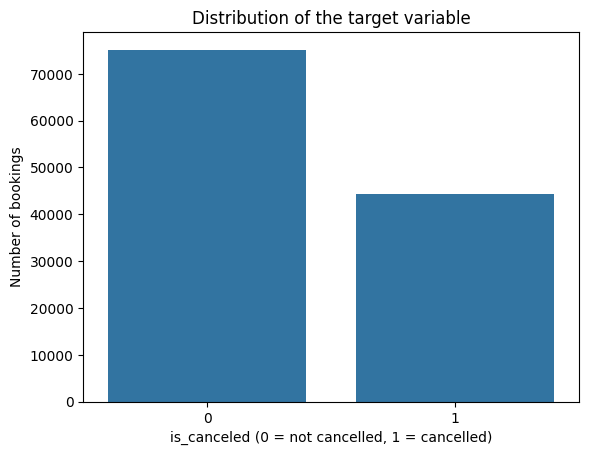

In [12]:
print(df['is_canceled'].value_counts())
print(df['is_canceled'].value_counts(normalize=True).round(4) * 100)

sns.countplot(x='is_canceled', data=df)
plt.title('Distribution of the target variable')
plt.xlabel('is_canceled (0 = not cancelled, 1 = cancelled)')
plt.ylabel('Number of bookings')
plt.show()

About 63% of the bookings were not cancelled and 37% were cancelled. The classes are **moderately imbalanced**: not as extreme as in fraud detection, but enough to make accuracy a misleading metric (a model always predicting "not cancelled" would reach 63% accuracy while detecting no cancellation). This confirms the choice of Recall, F1-score and PR-AUC made in the Business Understanding phase.

### 2.4 Exploratory analysis
The following analyses check how the cancellation rate changes across the main attributes, in order to verify the hypotheses formulated in the Business Understanding phase. The red dashed line in each plot shows the overall cancellation rate (37%).

In [ ]:
def plot_cancel_rate(data, col, title, order=None):
    rate = data.groupby(col, observed=True)['is_canceled'].mean() * 100
    if order is None:
        rate = rate.sort_values(ascending=False)
    else:
        rate = rate.reindex(order)
    ax = rate.plot(kind='bar', color='steelblue', figsize=(8, 4))
    ax.axhline(data['is_canceled'].mean() * 100, color='red', linestyle='--', label='Overall rate')
    ax.set_title(title)
    ax.set_ylabel('Cancellation rate (%)')
    ax.set_xlabel('')
    ax.legend()
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#### Hotel type

In [ ]:
plot_cancel_rate(df, 'hotel', 'Cancellation rate by hotel type')

The City Hotel has a much higher cancellation rate (41.7%) than the Resort Hotel (27.8%). Since the two hotels behave differently, the hotel type is an important feature for the model.

#### Lead time

In [ ]:
eda = df.copy()
eda['lead_time_group'] = pd.cut(eda['lead_time'],
                                bins=[-1, 7, 30, 90, 180, 365, 1000],
                                labels=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])
plot_cancel_rate(eda, 'lead_time_group', 'Cancellation rate by lead time (days)',
                 order=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])

The cancellation rate grows steadily with the lead time: it is 9.6% for bookings made within one week of arrival and reaches 67.7% for bookings made more than one year in advance (median lead time: 113 days for cancelled bookings vs 45 days for the others). This confirms the hypothesis of the Business Understanding: guests who book far in advance have more time to change their plans. From the hotel's point of view this is partly good news, since many cancellations come from early bookings, which leave time to resell the room.

#### Deposit type

In [ ]:
plot_cancel_rate(df, 'deposit_type', 'Cancellation rate by deposit type')
print(df['deposit_type'].value_counts())

In [ ]:
non_refund = df[df['deposit_type'] == 'Non Refund']
print(non_refund['hotel'].value_counts(), '\n')
print(non_refund['market_segment'].value_counts().head(), '\n')
print(non_refund['country'].value_counts().head(3))

This result is counter-intuitive: **99.4% of the Non Refund bookings were cancelled**, while bookings without deposit have a cancellation rate of 28.4%. One would expect a non-refundable deposit to discourage cancellations. Looking at these 14,587 bookings, almost all of them belong to the City Hotel, come from Portugal and from the Groups and Offline TA/TO segments: they are likely block reservations made by tour operators and later released, rather than individual guests losing their money. As a consequence, `deposit_type` will be a very strong predictor, but its effect should not be interpreted as "deposits cause cancellations", and the business recommendations on deposits must take this into account.

#### Market segment and customer history

In [ ]:
plot_cancel_rate(df, 'market_segment', 'Cancellation rate by market segment')

eda['has_previous_cancellations'] = (eda['previous_cancellations'] > 0).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'has_previous_cancellations', 'Cancellation rate by previous cancellations')

plot_cancel_rate(df, 'total_of_special_requests', 'Cancellation rate by number of special requests',
                 order=[0, 1, 2, 3, 4, 5])

- **Market segment**: Groups (61.1%) and online travel agencies (36.7%) cancel the most, while Direct (15.3%) and Corporate (18.7%) bookings are much more reliable.
- **Previous cancellations**: guests who already cancelled in the past cancel again in 91.6% of the cases, compared to 33.9% for the others.
- **Special requests**: the more special requests a guest makes, the less likely the booking is cancelled (47.7% with no requests, below 11% with four or more). Special requests are a sign of commitment to the stay.

The `Undefined` category of `market_segment` contains only 2 bookings and is not meaningful.

#### Correlation with the target

In [ ]:
numeric = df.select_dtypes(include='number').drop(columns=['agent', 'company'])
corr = numeric.corr()['is_canceled'].drop('is_canceled').sort_values()

corr.plot(kind='barh', color='steelblue', figsize=(8, 6))
plt.title('Correlation of numerical attributes with is_canceled')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

The strongest positive correlation is with `lead_time` (0.29) and `previous_cancellations` (0.11); the strongest negative ones are with `total_of_special_requests` (-0.23), `required_car_parking_spaces` (-0.20) and `booking_changes` (-0.14). All correlations are weak in absolute terms: no single numerical attribute explains cancellations alone, which suggests that a multivariate model is needed. Pearson correlation only captures linear relationships, so it is used here as a first indication.

#### Potential data leakage

In [ ]:
eda['room_changed'] = (eda['reserved_room_type'] != eda['assigned_room_type']).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'room_changed', 'Cancellation rate: assigned room different from reserved')

eda['parking'] = (eda['required_car_parking_spaces'] > 0).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'parking', 'Cancellation rate: parking space required')

Two attributes show a suspicious behaviour:
- when the assigned room differs from the reserved one, only 5.4% of bookings are cancelled (vs 41.6%);
- **no booking** with a required parking space was cancelled (0%).

This is not a real behaviour of the guests: the room is assigned and the parking space is registered mostly **at check-in**, so these values are only known for guests who actually arrived. They contain information about the outcome and would not be available at booking time, which is when the model has to make its prediction. They are therefore a form of **data leakage**, like `reservation_status`, and will be handled in Data Preparation.

### 2.5 Data quality

In [ ]:
print('Duplicated rows:', df.duplicated().sum())
print('Bookings with no guests:', ((df['adults'] + df['children'].fillna(0) + df['babies']) == 0).sum())
print('Negative adr:', (df['adr'] < 0).sum())
print('adr equal to 0:', (df['adr'] == 0).sum())
print('Max adr:', df['adr'].max())
print('"Undefined" in meal:', (df['meal'] == 'Undefined').sum())
print('"Undefined" in market_segment:', (df['market_segment'] == 'Undefined').sum())
print('"Undefined" in distribution_channel:', (df['distribution_channel'] == 'Undefined').sum())

The data quality checks highlight several issues to address in Data Preparation:
- **31,994 duplicated rows** (27% of the dataset). Since the dataset has no booking identifier, some of them may be different bookings with identical characteristics (e.g. several rooms of the same group); this choice will be discussed.
- **180 bookings with no guests** (adults, children and babies all equal to zero), which are not valid bookings.
- **`adr`** (average daily rate) has one negative value and an extreme maximum of 5,400 €, far above all other values; 1,959 bookings have a rate of 0 (e.g. complementary stays).
- **"Undefined" categories**: 1,169 in `meal` (which, according to the dataset documentation, has the same meaning as `SC`, i.e. no meal package), 2 in `market_segment` and 5 in `distribution_channel`.

## 3. Data Preparation

## 4. Modeling

## 5. Evaluation

## 6. Deployment